<h1 align='center'> Price prediction <h1/>

In [244]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [245]:
df=pd.read_csv('data/survey_results.csv')

print(df.shape)
df.head()

(30010, 17)


,respondent_id,age,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,flavor_preference,purchase_channel,packaging_preference,health_concerns,typical_consumption_situations,price_range
0,R00001,30,M,Urban,Working Professional,<10L,3-4 times,Newcomer,Medium (500 ml),0 to 1,Price,Traditional,Online,Simple,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",100-150
1,R00002,46,F,Metro,Working Professional,> 35L,5-7 times,Established,Medium (500 ml),2 to 4,Quality,Exotic,Retail Store,Premium,Medium (Moderately health-conscious),Social (eg. Parties),200-250
2,R00003,41,F,Rural,Working Professional,> 35L,3-4 times,Newcomer,Medium (500 ml),2 to 4,Availability,Traditional,Retail Store,Premium,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",200-250
3,R00004,33,F,Urban,Working Professional,16L - 25L,5-7 times,Newcomer,Medium (500 ml),0 to 1,Brand Reputation,Exotic,Online,Eco-Friendly,Low (Not very concerned),"Active (eg. Sports, gym)",150-200
4,R00005,23,M,Metro,Student,NaN,3-4 times,Established,Medium (500 ml),0 to 1,Availability,Traditional,Online,Premium,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",50-100


In [246]:
df.columns

Index(['respondent_id', 'age', 'gender', 'zone', 'occupation', 'income_levels',
       'consume_frequency(weekly)', 'current_brand',
       'preferable_consumption_size', 'awareness_of_other_brands',
       'reasons_for_choosing_brands', 'flavor_preference', 'purchase_channel',
       'packaging_preference', 'health_concerns',
       'typical_consumption_situations', 'price_range'],
      dtype='str')

In [247]:
df.duplicated().sum()

10

In [248]:
df[df.duplicated(keep=False)]

,respondent_id,age,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,flavor_preference,purchase_channel,packaging_preference,health_concerns,typical_consumption_situations,price_range
2308,R02309,27,M,Urban,Working Professional,16L - 25L,3-4 times,Newcomer,Small (250 ml),2 to 4,Brand Reputation,Traditional,Online,Simple,Medium (Moderately health-conscious),Social (eg. Parties),150-200
2309,R02309,27,M,Urban,Working Professional,16L - 25L,3-4 times,Newcomer,Small (250 ml),2 to 4,Brand Reputation,Traditional,Online,Simple,Medium (Moderately health-conscious),Social (eg. Parties),150-200
2665,R02665,61,M,Metro,Entrepreneur,16L - 25L,3-4 times,Established,Medium (500 ml),above 4,Brand Reputation,Exotic,Retail Store,Simple,High (Very health-conscious),"Active (eg. Sports, gym)",200-250
2666,R02665,61,M,Metro,Entrepreneur,16L - 25L,3-4 times,Established,Medium (500 ml),above 4,Brand Reputation,Exotic,Retail Store,Simple,High (Very health-conscious),"Active (eg. Sports, gym)",200-250
5150,R05149,21,M,Semi-Urban,Student,NaN,3-4 times,Established,Small (250 ml),2 to 4,Availability,Traditional,Retail Store,Simple,Low (Not very concerned),"Active (eg. Sports, gym)",50-100
5151,R05149,21,M,Semi-Urban,Student,NaN,3-4 times,Established,Small (250 ml),2 to 4,Availability,Traditional,Retail Store,Simple,Low (Not very concerned),"Active (eg. Sports, gym)",50-100
7793,R07791,25,M,Metro,Working Professional,<10L,3-4 times,Newcomer,Medium (500 ml),2 to 4,Availability,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
7794,R07791,25,M,Metro,Working Professional,<10L,3-4 times,Newcomer,Medium (500 ml),2 to 4,Availability,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
8515,R08512,20,F,Metro,Student,NaN,5-7 times,Established,Large (1 L),0 to 1,Price,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
8516,R08512,20,F,Metro,Student,NaN,5-7 times,Established,Large (1 L),0 to 1,Price,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150


These are the Occurances of the duplicates in the dataset, Lets keep one occurance and remove the duplicate occurances

In [249]:
df = df.drop_duplicates()

In [250]:
df.info()

<class 'pandas.DataFrame'>
Index: 30000 entries, 0 to 30009
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   respondent_id                   30000 non-null  str  
 1   age                             30000 non-null  int64
 2   gender                          30000 non-null  str  
 3   zone                            30000 non-null  str  
 4   occupation                      30000 non-null  str  
 5   income_levels                   21939 non-null  str  
 6   consume_frequency(weekly)       29992 non-null  str  
 7   current_brand                   30000 non-null  str  
 8   preferable_consumption_size     30000 non-null  str  
 9   awareness_of_other_brands       30000 non-null  str  
 10  reasons_for_choosing_brands     30000 non-null  str  
 11  flavor_preference               30000 non-null  str  
 12  purchase_channel                29990 non-null  str  
 13  packaging_prefere

In [251]:
df.describe()

,age
count,30000.000000
mean,33.048167
std,13.438904
min,18.000000
25%,23.000000
50%,31.000000
75%,40.000000
max,604.000000


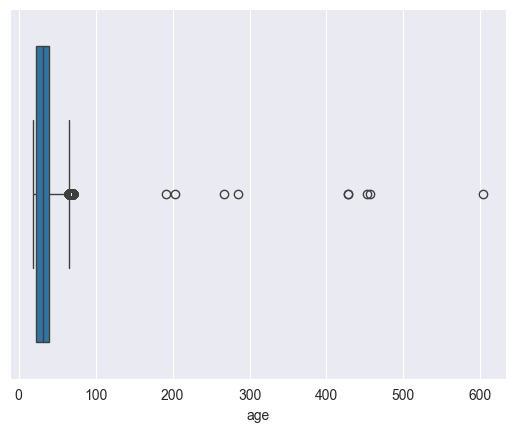

In [252]:
sns.boxplot(x=df['age'])
plt.show()

we found that the age column with many outliers

In [253]:
print(df['age'].value_counts().sort_index())

age
18     1320
19     1352
20     1261
21     1294
22     1327
       ... 
285       1
428       2
453       1
457       1
604       1
Name: count, Length: 61, dtype: int64


In [254]:
(df['age'] <1).sum()

0

In [255]:
df[df['age'] > 100]

,respondent_id,age,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,flavor_preference,purchase_channel,packaging_preference,health_concerns,typical_consumption_situations,price_range
3099,R03098,453,M,Metro,Working Professional,26L - 35L,3-4 times,Established,Medium (500 ml),2 to 4,Brand Reputation,Traditional,Retail Store,Premium,Medium (Moderately health-conscious),Social (eg. Parties),200-250
6262,R06260,428,M,Urban,Entrepreneur,16L - 25L,5-7 times,Established,Large (1 L),above 4,Quality,Exotic,Online,Simple,High (Very health-conscious),Social (eg. Parties),200-250
12403,R12398,604,M,Metro,Retired,<10L,0-2 times,Newcomer,Small (250 ml),2 to 4,Availability,Traditional,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
22549,R22542,457,M,Metro,Working Professional,16L - 25L,3-4 times,Newcomer,Small (250 ml),2 to 4,Price,Traditional,Online,Premium,High (Very health-conscious),Casual (eg. At home),200-250
22918,R22911,267,F,Metro,Working Professional,16L - 25L,3-4 times,Established,Medium (500 ml),above 4,Brand Reputation,Exotic,Online,Eco-Friendly,Low (Not very concerned),"Active (eg. Sports, gym)",150-200
24958,R24950,285,M,Semi-Urban,Working Professional,> 35L,0-2 times,Newcomer,Small (250 ml),2 to 4,Price,Traditional,Online,Simple,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",150-200
24960,R24952,192,F,Urban,Student,NaN,3-4 times,Newcomer,Medium (500 ml),0 to 1,Price,Traditional,Online,Simple,Low (Not very concerned),"Active (eg. Sports, gym)",50-100
25105,R25096,203,M,Metro,Working Professional,16L - 25L,0-2 times,Established,Small (250 ml),2 to 4,Brand Reputation,Exotic,Retail Store,Premium,High (Very health-conscious),"Active (eg. Sports, gym)",150-200
28770,R28761,428,F,Rural,Working Professional,26L - 35L,0-2 times,Established,Small (250 ml),2 to 4,Brand Reputation,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),150-200


In [256]:
df = df[df['age'] <= 100]

In [257]:
(df['age'] > 100).sum()

0

In [258]:
df.isnull().sum()

respondent_id                        0
age                                  0
gender                               0
zone                                 0
occupation                           0
income_levels                     8060
consume_frequency(weekly)            8
current_brand                        0
preferable_consumption_size          0
awareness_of_other_brands            0
reasons_for_choosing_brands          0
flavor_preference                    0
purchase_channel                    10
packaging_preference                 0
health_concerns                      0
typical_consumption_situations       0
price_range                          0
dtype: int64

income_levels, purchase_channel, consume_frequency(weekly) have the Missing Values

### income_levels column

In [259]:
df.income_levels.value_counts()

income_levels
16L - 25L    5897
10L - 15L    5251
<10L         4661
26L - 35L    3872
> 35L        2250
Name: count, dtype: int64

In [260]:
df.income_levels = df.income_levels.fillna('Not Reported')

### purchase_channel column

In [261]:
df['purchase_channel'].isnull().sum()

10

In [262]:
df['purchase_channel'] = df['purchase_channel'].fillna(df['purchase_channel'].mode().iloc[0])

In [263]:
df['purchase_channel'].isnull().sum()

0

### consume_frequency(weekly) column

In [264]:
df['consume_frequency(weekly)'].mode().iloc[0]

'3-4 times'

In [265]:
df['consume_frequency(weekly)'] = df['consume_frequency(weekly)'].fillna(df['consume_frequency(weekly)'].mode().iloc[0])

In [266]:
df['consume_frequency(weekly)'].isnull().sum()


0

In [267]:
df.columns

Index(['respondent_id', 'age', 'gender', 'zone', 'occupation', 'income_levels',
       'consume_frequency(weekly)', 'current_brand',
       'preferable_consumption_size', 'awareness_of_other_brands',
       'reasons_for_choosing_brands', 'flavor_preference', 'purchase_channel',
       'packaging_preference', 'health_concerns',
       'typical_consumption_situations', 'price_range'],
      dtype='str')

In [268]:
df.zone.value_counts()

zone
Metro         11906
Urban         10686
Semi-Urban     5274
Rural          2116
urbna             5
Metor             4
Name: count, dtype: int64

In [269]:
df['zone'] = df['zone'].replace({
    'Metor': 'Metro',
    'urbna': 'Urban'
})

In [270]:
df.zone.value_counts()

zone
Metro         11910
Urban         10691
Semi-Urban     5274
Rural          2116
Name: count, dtype: int64

In [271]:
df.current_brand.value_counts()


current_brand
Established    15442
Newcomer       14499
newcomer          30
Establishd        20
Name: count, dtype: int64

In [272]:
df['current_brand'] = df['current_brand'].replace({
    'Establishd': 'Established',
    'newcomer': 'Newcomer'
})

In [273]:
df.current_brand.value_counts()


current_brand
Established    15462
Newcomer       14529
Name: count, dtype: int64

## Feature Engg

In [274]:
def age_groups(age):
    if age >= 18 and age <= 25:
        return "18-25"
    elif age >= 26 and age <= 35:
        return "26-35"
    elif age >= 36 and age <= 45:
        return "36-45"
    elif age >= 46 and age <= 55:
        return "46-55"
    elif age >= 56 and age <= 70:
        return "56-70"
    elif age>70:
        return "70+"

df['age_group'] = df['age'].apply(age_groups)


In [275]:
df = df.drop('age',axis=1)

In [276]:
df["consume_frequency(weekly)_score"] = df["consume_frequency(weekly)"].replace({
    "0-2 times": 1,
    "3-4 times": 2,
    "5-7 times": 3
})

df["awareness_of_other_brands_score"] = df["awareness_of_other_brands"].replace({
    "0 to 1": 1,
    "2 to 4": 2,
    "above 4": 3
})

df['cf_ab_score'] = (
    df["consume_frequency(weekly)_score"] /
    (df["awareness_of_other_brands_score"] + df["consume_frequency(weekly)_score"])
).round(2)

In [277]:
df['cf_ab_score'].max()

0.75

In [278]:
df['zone_score'] = df['zone'].map({
    "Metro" : 4,
    "Urban" : 3,
    "Rural" : 1,
    "Semi-Urban" : 2
})
df['income_levels_score'] = df['income_levels'].map({
    "<10L": 1,
    "10L - 15L": 2,
    "16L - 25L": 3,
    "26L - 35L": 4,
    "> 35L" : 5,
    "Not Reported" : 0
})

df["zas_score"] = df['zone_score'] * df['income_levels_score']

In [279]:
len(df["zas_score"].unique())

14

In [280]:
df['current_brand'].value_counts()

current_brand
Established    15462
Newcomer       14529
Name: count, dtype: int64

In [281]:
df['bsi'] = (
    (df['current_brand'] != 'Established') &
    (df['reasons_for_choosing_brands'].isin(['Price', 'Quality']))
).astype(int)

In [282]:
df['bsi'].value_counts()

bsi
0    20816
1     9175
Name: count, dtype: int64

In [283]:
pd.crosstab(df['age_group'], df['occupation'])

occupation,Entrepreneur,Retired,Student,Working Professional
age_group,,,,
18-25,535,0,7328,2605
26-35,1826,0,697,6570
36-45,1619,0,0,4353
46-55,799,0,0,2167
56-70,221,1130,35,106


In [284]:
df[(df['age_group'] == '56-70') & (df['occupation'] == 'Student')]

,respondent_id,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,...,typical_consumption_situations,price_range,age_group,consume_frequency(weekly)_score,awareness_of_other_brands_score,cf_ab_score,zone_score,income_levels_score,zas_score,bsi
182,R00183,F,Urban,Student,Not Reported,5-7 times,Established,Large (1 L),above 4,Price,...,Casual (eg. At home),150-200,56-70,3,3,0.5,3,0,0,0
3526,R03525,F,Semi-Urban,Student,Not Reported,0-2 times,Established,Medium (500 ml),0 to 1,Price,...,"Active (eg. Sports, gym)",50-100,56-70,1,1,0.5,2,0,0,0
3527,R03526,M,Semi-Urban,Student,Not Reported,0-2 times,Newcomer,Small (250 ml),2 to 4,Price,...,Casual (eg. At home),100-150,56-70,1,2,0.33,2,0,0,1
3772,R03771,M,Metro,Student,Not Reported,5-7 times,Newcomer,Medium (500 ml),2 to 4,Availability,...,"Active (eg. Sports, gym)",150-200,56-70,3,2,0.6,4,0,0,0
4033,R04032,M,Urban,Student,Not Reported,3-4 times,Established,Medium (500 ml),0 to 1,Price,...,Social (eg. Parties),150-200,56-70,2,1,0.67,3,0,0,0
6545,R06543,F,Urban,Student,Not Reported,5-7 times,Newcomer,Medium (500 ml),0 to 1,Price,...,Social (eg. Parties),150-200,56-70,3,1,0.75,3,0,0,1
6594,R06592,M,Semi-Urban,Student,Not Reported,5-7 times,Established,Medium (500 ml),0 to 1,Availability,...,Casual (eg. At home),100-150,56-70,3,1,0.75,2,0,0,0
6648,R06646,F,Semi-Urban,Student,Not Reported,0-2 times,Established,Medium (500 ml),2 to 4,Price,...,Casual (eg. At home),100-150,56-70,1,2,0.33,2,0,0,0
7420,R07418,F,Rural,Student,Not Reported,3-4 times,Established,Small (250 ml),0 to 1,Price,...,"Active (eg. Sports, gym)",100-150,56-70,2,1,0.67,1,0,0,0
7596,R07594,M,Urban,Student,Not Reported,5-7 times,Newcomer,Medium (500 ml),2 to 4,Price,...,"Active (eg. Sports, gym)",200-250,56-70,3,2,0.6,3,0,0,1


In [285]:
df = df[~((df['age_group'] == '56-70') & (df['occupation'] == 'Student'))]

In [286]:
pd.crosstab(df['age_group'], df['occupation'])

occupation,Entrepreneur,Retired,Student,Working Professional
age_group,,,,
18-25,535,0,7328,2605
26-35,1826,0,697,6570
36-45,1619,0,0,4353
46-55,799,0,0,2167
56-70,221,1130,0,106


In [287]:
df['bsi'].value_counts()

bsi
0    20796
1     9160
Name: count, dtype: int64

In [288]:
df.columns

Index(['respondent_id', 'gender', 'zone', 'occupation', 'income_levels',
       'consume_frequency(weekly)', 'current_brand',
       'preferable_consumption_size', 'awareness_of_other_brands',
       'reasons_for_choosing_brands', 'flavor_preference', 'purchase_channel',
       'packaging_preference', 'health_concerns',
       'typical_consumption_situations', 'price_range', 'age_group',
       'consume_frequency(weekly)_score', 'awareness_of_other_brands_score',
       'cf_ab_score', 'zone_score', 'income_levels_score', 'zas_score', 'bsi'],
      dtype='str')

In [289]:
X= df.drop(["respondent_id",'price_range',"awareness_of_other_brands_score","consume_frequency(weekly)_score","income_levels_score", "zone_score",  ], axis=1)
y = df[['price_range']]

In [290]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [291]:
X_train.columns

Index(['gender', 'zone', 'occupation', 'income_levels',
       'consume_frequency(weekly)', 'current_brand',
       'preferable_consumption_size', 'awareness_of_other_brands',
       'reasons_for_choosing_brands', 'flavor_preference', 'purchase_channel',
       'packaging_preference', 'health_concerns',
       'typical_consumption_situations', 'age_group', 'cf_ab_score',
       'zas_score', 'bsi'],
      dtype='str')

In [292]:
y_train.columns

Index(['price_range'], dtype='str')

In [293]:
len(X_train), len(X_test), len(y_train), len(y_test)

(22467, 7489, 22467, 7489)

# Feature Encoding

In [294]:
df.columns

Index(['respondent_id', 'gender', 'zone', 'occupation', 'income_levels',
       'consume_frequency(weekly)', 'current_brand',
       'preferable_consumption_size', 'awareness_of_other_brands',
       'reasons_for_choosing_brands', 'flavor_preference', 'purchase_channel',
       'packaging_preference', 'health_concerns',
       'typical_consumption_situations', 'price_range', 'age_group',
       'consume_frequency(weekly)_score', 'awareness_of_other_brands_score',
       'cf_ab_score', 'zone_score', 'income_levels_score', 'zas_score', 'bsi'],
      dtype='str')

In [295]:
df['preferable_consumption_size'].value_counts()

preferable_consumption_size
Medium (500 ml)    13205
Small (250 ml)      9709
Large (1 L)         7042
Name: count, dtype: int64

In [296]:
print(df['health_concerns'].value_counts(dropna=False))

health_concerns
High (Very health-conscious)            11893
Medium (Moderately health-conscious)    10624
Low (Not very concerned)                 7439
Name: count, dtype: int64


## Label Encoding

In [298]:
# Columns to ordinal encode
col_to_label_encode = [
    'income_levels',
    'age_group',
    'health_concerns',
    'consume_frequency(weekly)',
    'preferable_consumption_size'
]

# Define ordinal mappings
ordinal_mappings = {
    'income_levels': {
        'Not Reported': 0,
        '<10L': 1,
        '10L - 15L': 2,
        '16L - 25L': 3,
        '26L - 35L': 4,
        '> 35L': 5
    },

    'age_group': {
        '18-25': 1,
        '26-35': 2,
        '36-45': 3,
        '46-55': 4,
        '56-70': 5,
        '70+': 6
    },

    'health_concerns': {
        'Low (Not very concerned)': 1,
        'Medium (Moderately health-conscious)': 2,
        'High (Very health-conscious)': 3
    },

    'consume_frequency(weekly)': {
        '0-2 times': 1,
        '3-4 times': 2,
        '5-7 times': 3
    },

    'preferable_consumption_size': {
        'Small (250 ml)': 1,
        'Medium (500 ml)': 2,
        'Large (1 L)': 3
    }
}

# Apply the same mappings to training and testing data
for col, mapping in ordinal_mappings.items():
    X_train[col] = X_train[col].map(mapping)
    X_test[col] = X_test[col].map(mapping)

# Verify the encoding
print(X_train[col_to_label_encode].head())
print("\nMissing values in X_train:")
print(X_train[col_to_label_encode].isnull().sum())

print("\nMissing values in X_test:")
print(X_test[col_to_label_encode].isnull().sum())

       income_levels  age_group  health_concerns  consume_frequency(weekly)  \
8391               2          1                1                          1   
26395              3          1                2                          3   
11276              0          1                2                          2   
9110               3          2                1                          2   
3373               3          2                2                          1   

       preferable_consumption_size  
8391                             1  
26395                            2  
11276                            1  
9110                             3  
3373                             3  

Missing values in X_train:
income_levels                  0
age_group                      0
health_concerns                0
consume_frequency(weekly)      0
preferable_consumption_size    0
dtype: int64

Missing values in X_test:
income_levels                  0
age_group                      0
heal

## One Hot Encoding

In [299]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify remaining categorical columns
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'str']).columns.tolist()

# One-hot encoder
ohe = OneHotEncoder(
    handle_unknown='ignore',
    drop='first',
    sparse_output=False
)

# Fit on training data and transform both datasets
X_train_encoded = ohe.fit_transform(X_train[categorical_cols])
X_test_encoded = ohe.transform(X_test[categorical_cols])

# Convert encoded arrays to DataFrames
import pandas as pd

X_train_ohe = pd.DataFrame(
    X_train_encoded,
    columns=ohe.get_feature_names_out(categorical_cols),
    index=X_train.index
)

X_test_ohe = pd.DataFrame(
    X_test_encoded,
    columns=ohe.get_feature_names_out(categorical_cols),
    index=X_test.index
)

# Drop original categorical columns and join encoded columns
X_train = pd.concat([X_train.drop(columns=categorical_cols), X_train_ohe], axis=1)
X_test = pd.concat([X_test.drop(columns=categorical_cols), X_test_ohe], axis=1)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (22467, 32)
X_test shape: (7489, 32)


In [302]:
y_test.value_counts()

price_range
200-250        2430
150-200        2223
100-150        1930
50-100          906
Name: count, dtype: int64

In [303]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Fit on training target and transform both
y_train = le.fit_transform(y_train.values.ravel())
y_test = le.transform(y_test.values.ravel())

print("Target mapping:")
for i, category in enumerate(le.classes_):
    print(f"{category} -> {i}")

Target mapping:
100-150 -> 0
150-200 -> 1
200-250 -> 2
50-100 -> 3


In [306]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 7489 entries, 11981 to 16840
Data columns (total 32 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   income_levels                                        7489 non-null   int64  
 1   consume_frequency(weekly)                            7489 non-null   int64  
 2   preferable_consumption_size                          7489 non-null   int64  
 3   health_concerns                                      7489 non-null   int64  
 4   age_group                                            7489 non-null   int64  
 5   zas_score                                            7489 non-null   int64  
 6   bsi                                                  7489 non-null   int32  
 7   gender_M                                             7489 non-null   float64
 8   zone_Rural                                           7489 non-null   float64
 9

In [319]:
import numpy as np

corr_matrix = X_train.corr(numeric_only=True)

# Keep only the upper triangle to avoid duplicate pairs
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']

high_corr = high_corr[
    high_corr['Correlation'].abs() > 0.80
].sort_values(
    by='Correlation',
    key=abs,
    ascending=False
)

print(high_corr)

       Feature 1  Feature 2  Correlation
5  income_levels  zas_score     0.903464


## Model Selection:
  Testing the following machine learning models on the prepared data:
* Gaussian Naive Bayes
* Logistic Regression
* Support Vector Machine (SVM)
* Random Forest
* XGBoost
* Light Gradient Boosting Machine (Light GBM)

### Logistic Regression

In [308]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8477767392175191
              precision    recall  f1-score   support

           0       0.81      0.83      0.82      1930
           1       0.81      0.81      0.81      2223
           2       0.91      0.91      0.91      2430
           3       0.85      0.82      0.83       906

    accuracy                           0.85      7489
   macro avg       0.85      0.84      0.84      7489
weighted avg       0.85      0.85      0.85      7489



In [309]:
from sklearn.naive_bayes import GaussianNB

# Initialize the model
gnb = GaussianNB()

# Train the model
gnb.fit(X_train, y_train)

# Make predictions
y_pred = gnb.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))



Accuracy: 0.5860595540125517

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.36      0.42      1930
           1       0.57      0.32      0.41      2223
           2       0.70      0.89      0.78      2430
           3       0.47      0.92      0.62       906

    accuracy                           0.59      7489
   macro avg       0.56      0.62      0.56      7489
weighted avg       0.58      0.59      0.56      7489



In [310]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

# Initialize SVM model
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale')
)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8998531179062625

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.89      0.89      1930
           1       0.85      0.88      0.87      2223
           2       0.94      0.93      0.93      2430
           3       0.93      0.91      0.92       906

    accuracy                           0.90      7489
   macro avg       0.90      0.90      0.90      7489
weighted avg       0.90      0.90      0.90      7489



In [311]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9026572306048871

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.89      1930
           1       0.86      0.90      0.88      2223
           2       0.94      0.94      0.94      2430
           3       0.92      0.88      0.90       906

    accuracy                           0.90      7489
   macro avg       0.90      0.90      0.90      7489
weighted avg       0.90      0.90      0.90      7489



In [313]:
from lightgbm import LGBMClassifier

# Initialize the model
lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train the model
lgbm_model.fit(X_train, y_train)

# Make predictions
y_pred = lgbm_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9222860194952597

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.90      0.90      1930
           1       0.90      0.91      0.90      2223
           2       0.96      0.96      0.96      2430
           3       0.92      0.91      0.91       906

    accuracy                           0.92      7489
   macro avg       0.92      0.92      0.92      7489
weighted avg       0.92      0.92      0.92      7489



In [316]:
from xgboost import XGBClassifier

# Initialize the model
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    objective='multi:softprob',
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred = xgb_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9082654560021365

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.89      1930
           1       0.87      0.90      0.88      2223
           2       0.96      0.94      0.95      2430
           3       0.93      0.90      0.91       906

    accuracy                           0.91      7489
   macro avg       0.91      0.90      0.91      7489
weighted avg       0.91      0.91      0.91      7489



In [317]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# 1. Initialize LightGBM
lgbm = LGBMClassifier(
    random_state=42,
    verbosity=-1,
    n_jobs=1,
    subsample_freq=1
)

# 2. Define hyperparameter search space
param_dist = {
    'n_estimators': [100, 200, 300, 500, 700],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 50, 70, 100],
    'max_depth': [-1, 5, 10, 15, 20],
    'min_child_samples': [10, 20, 30, 50],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.01, 0.1, 1.0],
    'reg_lambda': [0, 0.01, 0.1, 1.0, 5.0]
}

# 3. Randomized hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_dist,
    n_iter=40,
    scoring='accuracy',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 4. Train using cross-validation
random_search.fit(X_train, y_train)

# 5. Get the best model
best_lgbm = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(random_search.best_score_)

# 6. Evaluate on unseen test data
y_pred = best_lgbm.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters:
{'subsample': 0.8, 'reg_lambda': 0, 'reg_alpha': 1.0, 'num_leaves': 100, 'n_estimators': 700, 'min_child_samples': 10, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

Best Cross-Validation Accuracy:
0.925312460038961

Test Accuracy:
0.9270930698357591

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.91      0.91      1930
           1       0.91      0.92      0.91      2223
           2       0.96      0.96      0.96      2430
           3       0.92      0.92      0.92       906

    accuracy                           0.93      7489
   macro avg       0.92      0.92      0.92      7489
weighted avg       0.93      0.93      0.93      7489



In [318]:
# Get the best model
best_model = random_search.best_estimator_

# Best hyperparameters
print("Best Parameters:", random_search.best_params_)

# Evaluate the best model
y_pred = best_model.predict(X_test)

from sklearn.metrics import accuracy_score

print("Best CV Accuracy:", random_search.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Best Parameters: {'subsample': 0.8, 'reg_lambda': 0, 'reg_alpha': 1.0, 'num_leaves': 100, 'n_estimators': 700, 'min_child_samples': 10, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}
Best CV Accuracy: 0.925312460038961
Test Accuracy: 0.9270930698357591
